In [2]:
#Build customer-level RFM data
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_pickle("../data/orders_clean.pkl")
snapshot = df["purchase_ts"].max().normalize() + pd.Timedelta(days=1)

cust = df.groupby("customer_unique_id").agg(
    last_purchase=("purchase_ts", "max"),
    frequency=("order_id", "nunique"),
    monetary=("payment_value", "sum"),
    avg_order_value=("payment_value", "mean"),
    avg_review=("review_score", "mean"),
    late_share=("is_late", "mean"),
    state=("state", "last"),
)
cust["recency_days"] = (snapshot - cust["last_purchase"]).dt.days
cust["m_score"] = pd.qcut(cust["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

print(cust.shape)
cust.describe().round(1)

(94707, 9)


,last_purchase,frequency,monetary,avg_order_value,avg_review,late_share,recency_days,m_score
count,94707,94707.0,94707.0,94707.0,94027.0,93096.0,94707.0,94707.0
mean,2018-01-04 15:24:35.014117,1.0,165.6,160.7,4.1,0.1,237.0,3.0
min,2017-01-05 11:56:06,1.0,9.6,9.6,1.0,0.0,0.0,1.0
25%,2017-09-17 23:59:03.500000,1.0,63.1,62.4,4.0,0.0,114.0,2.0
50%,2018-01-22 21:43:28,1.0,107.9,105.7,5.0,0.0,219.0,3.0
75%,2018-05-07 13:29:19,1.0,182.9,176.9,5.0,0.0,345.5,4.0
max,2018-08-29 15:00:37,16.0,13664.1,13664.1,5.0,1.0,601.0,5.0
std,NaN,0.2,226.8,220.0,1.3,0.3,151.2,1.4


In [3]:
#Rule-based RFM segments
f, r, m = cust["frequency"], cust["recency_days"], cust["m_score"]
conditions = [
    (f >= 2) & (r <= 180),
    (f >= 2) & (r > 180),
    (f == 1) & (r <= 90) & (m >= 4),
    (f == 1) & (r <= 90),
    (f == 1) & (r <= 270),
    (f == 1) & (m >= 4),
]
names = ["Repeat – active", "Repeat – lapsed", "New – high value",
         "New", "Recent one-timers", "Lapsed – high value"]
cust["segment"] = np.select(conditions, names, default="Lapsed one-timers")

seg = cust.groupby("segment").agg(
    customers=("frequency", "size"),
    revenue=("monetary", "sum"),
    avg_order_value=("avg_order_value", "mean"),
    median_recency=("recency_days", "median"),
    avg_review=("avg_review", "mean"),
    late_share=("late_share", "mean"),
)
seg["pct_customers"] = (seg["customers"] / seg["customers"].sum() * 100).round(1)
seg["pct_revenue"] = (seg["revenue"] / seg["revenue"].sum() * 100).round(1)
seg.sort_values("revenue", ascending=False).round(2)

,customers,revenue,avg_order_value,median_recency,avg_review,late_share,pct_customers,pct_revenue
segment,,,,,,,,
Recent one-timers,37580,5974772.25,158.99,178.0,4.01,0.11,39.7,38.1
Lapsed – high value,13660,4230469.35,309.70,383.0,4.08,0.07,14.4,27.0
New – high value,7137,2159111.71,302.52,42.0,4.23,0.05,7.5,13.8
Lapsed one-timers,22514,1638527.40,72.78,386.0,4.16,0.06,23.8,10.4
New,10941,797677.91,72.91,40.0,4.32,0.06,11.6,5.1
Repeat – lapsed,1613,482735.71,144.02,299.0,4.11,0.07,1.7,3.1
Repeat – active,1262,403862.84,148.09,91.0,4.24,0.08,1.3,2.6


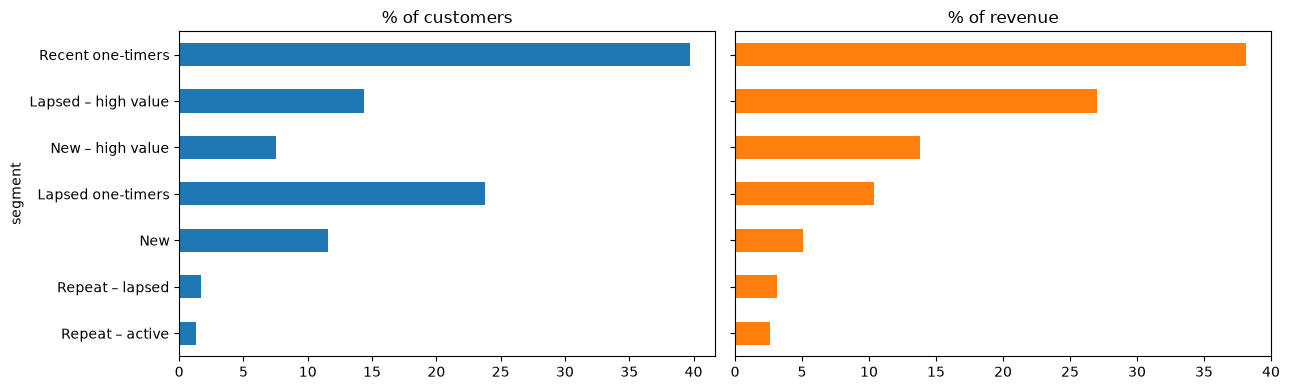

In [4]:
#Chart
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
order = seg.sort_values("revenue").index
seg.loc[order, "pct_customers"].plot.barh(ax=ax[0], title="% of customers")
seg.loc[order, "pct_revenue"].plot.barh(ax=ax[1], color="tab:orange", title="% of revenue")
plt.tight_layout(); plt.show()

In [5]:
#K-Means (data-driven clusters)
X = cust[["recency_days", "frequency", "monetary", "avg_review", "late_share"]].copy()
X["avg_review"] = X["avg_review"].fillna(X["avg_review"].median())
X["late_share"] = X["late_share"].fillna(0)
for c in ["recency_days", "frequency", "monetary"]:
    X[c] = np.log1p(X[c])
Xs = StandardScaler().fit_transform(X)

sample = np.random.default_rng(42).choice(len(Xs), 10000, replace=False)
rows = []
for k in range(2, 8):
    km = KMeans(k, n_init=10, random_state=42).fit(Xs)
    rows.append({"k": k, "inertia": km.inertia_,
                 "silhouette": silhouette_score(Xs[sample], km.labels_[sample])})
pd.DataFrame(rows).round(3)

,k,inertia,silhouette
0,2,368618.266,0.507
1,3,278507.014,0.539
2,4,220585.681,0.325
3,5,171928.322,0.364
4,6,136016.049,0.343
5,7,124098.030,0.308


In [6]:
#Profile the clusters. Set K to the value with the best silhouette, or a nearby value you can explain in business terms:
K = 4
km = KMeans(K, n_init=10, random_state=42).fit(Xs)
cust["cluster"] = km.labels_

profile = cust.groupby("cluster").agg(
    customers=("frequency", "size"),
    recency_days=("recency_days", "median"),
    frequency=("frequency", "mean"),
    avg_spend=("monetary", "mean"),
    avg_review=("avg_review", "mean"),
    late_share=("late_share", "mean"),
)
profile["share"] = (profile["customers"] / profile["customers"].sum()).round(3)
profile.round(2)

,customers,recency_days,frequency,avg_spend,avg_review,late_share,share
cluster,,,,,,,
0,64230,277.0,1.00,154.85,4.20,0.00,0.68
1,7399,188.0,1.00,173.97,2.56,1.00,0.08
2,2875,200.0,2.11,308.38,4.17,0.07,0.03
3,20203,53.0,1.00,176.56,4.40,0.00,0.21


In [7]:
cust.reset_index().to_pickle("../data/customers_segmented.pkl")

In [8]:
from pathlib import Path
art = Path("../artifacts"); art.mkdir(exist_ok=True)

cluster_names = {0: "Lapsed satisfied one-timers", 1: "Unhappy: late delivery",
                 2: "Repeat buyers", 3: "New satisfied customers"}
cust["cluster_name"] = cust["cluster"].map(cluster_names)

seg.reset_index().to_csv(art / "segment_summary.csv", index=False)
profile.assign(cluster_name=profile.index.map(cluster_names)).reset_index() \
       .to_csv(art / "cluster_profile.csv", index=False)
cust.reset_index()[["customer_unique_id", "segment", "cluster_name", "recency_days", "frequency",
                    "monetary", "avg_review", "late_share", "state"]] \
    .to_csv(art / "customer_segments.csv", index=False)
cust.reset_index().to_pickle("../data/customers_segmented.pkl")
print("saved")

saved


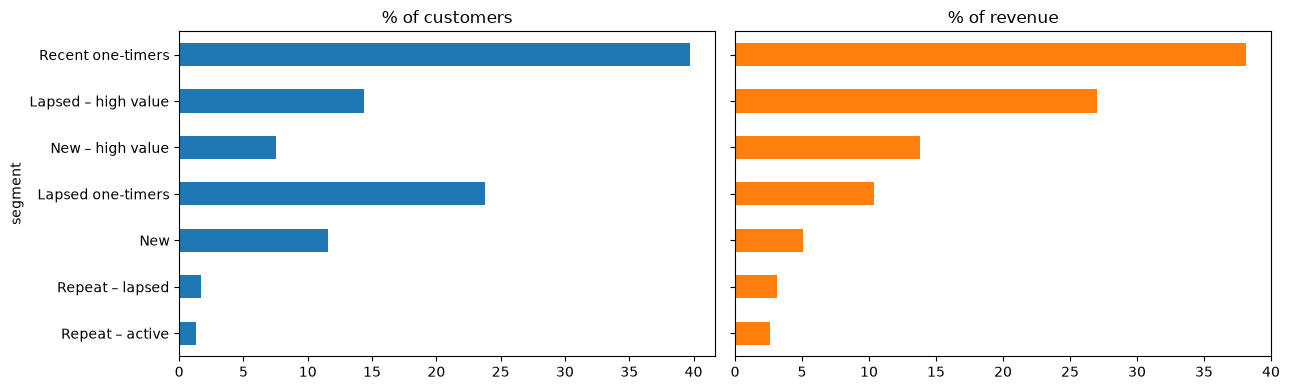

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
order = seg.sort_values("revenue").index
seg.loc[order, "pct_customers"].plot.barh(ax=ax[0], title="% of customers")
seg.loc[order, "pct_revenue"].plot.barh(ax=ax[1], color="tab:orange", title="% of revenue")
plt.tight_layout()
plt.savefig("../reports/figures/05_rfm_segments.png", dpi=150, bbox_inches="tight")
plt.show()